# 01 - Dataset de pares de acciones

**Qué queremos predecir:** dada una fecha de corte, cuánto se van a correlacionar dos acciones
en los **próximos 60 días hábiles**. Esa correlación futura es el *target*; todo lo que se sabe hasta
la fecha de corte son las *features*.

Este notebook arma el dataset paso a paso (el mismo que genera `backend/app/dataset.py`) y muestra
por qué no hay *leakage* (fuga de información del futuro hacia las features).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent          # el notebook corre desde notebooks/
sys.path.append(str(RAIZ / "backend"))  # para importar app.dataset y app.modelo
DATA = RAIZ / "data"

plt.rcParams["figure.figsize"] = (8, 4)

## 1. Datos crudos

`precios.csv` tiene el precio ajustado diario de 30 acciones más `SPY` (el índice de mercado que usamos
para calcular beta). `sectores.csv` dice a qué sector pertenece cada acción.

In [2]:
precios = pd.read_csv(DATA / "precios.csv", index_col="fecha", parse_dates=True)
sectores = pd.read_csv(DATA / "sectores.csv").set_index("ticker")["sector"]

print("precios:", precios.shape, "|", precios.index.min().date(), "a", precios.index.max().date())
print("NaN en precios:", int(precios.isna().sum().sum()))
sectores.value_counts()

precios: (2516, 31) | 2014-01-02 a 2023-12-29
NaN en precios: 0


sector
Consumo Secundario    4
Tecnología            3
Consumo Primario      3
Salud                 3
Financiero            3
Energía               3
Industriales          3
Comunicaciones        2
Materiales            2
Servicios Publicos    2
Inmobiliario          2
Name: count, dtype: int64

## 2. De precios a retornos

Los precios no sirven para medir correlación (casi todos suben con el tiempo y eso genera correlaciones
falsas). Trabajamos con **retornos diarios**: `r_t = P_t / P_{t-1} - 1`.

In [3]:
retornos = precios.pct_change().dropna()
retornos[["AAPL", "MSFT", "KO", "PG"]].describe().round(4)

,AAPL,MSFT,KO,PG
count,2515.0000,2515.0000,2515.0000,2515.0000
mean,0.0011,0.0011,0.0003,0.0004
std,0.0179,0.0171,0.0113,0.0115
min,-0.1286,-0.1474,-0.0967,-0.0874
25%,-0.0071,-0.0068,-0.0046,-0.0048
50%,0.0009,0.0009,0.0006,0.0006
75%,0.0102,0.0098,0.0058,0.0060
max,0.1198,0.1422,0.0648,0.1201


## 3. La correlación entre dos acciones cambia con el tiempo

Esto es lo que justifica el problema: si la correlación fuera constante no haría falta un modelo.
Graficamos la correlación móvil de 90 días de dos pares: uno del mismo sector (KO-PG) y otro
de distinto sector (AAPL-KO).

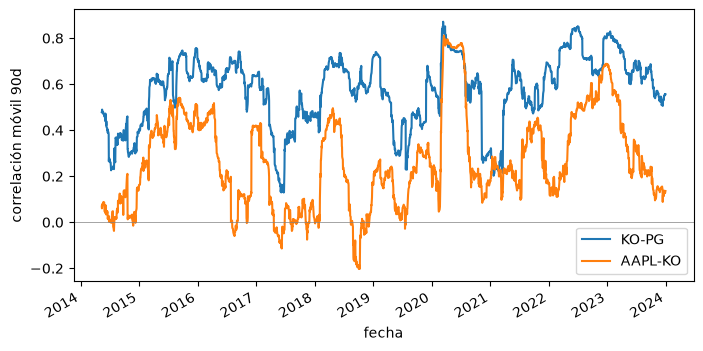

In [4]:
fig, eje = plt.subplots()
for a, b in [("KO", "PG"), ("AAPL", "KO")]:
    retornos[a].rolling(90).corr(retornos[b]).plot(ax=eje, label=f"{a}-{b}")
eje.axhline(0, color="gray", lw=0.5)
eje.set_ylabel("correlación móvil 90d")
eje.legend()
plt.show()

## 4. Features de un par en una fecha de corte (a mano)

Elegimos una fecha de corte `i` (cada 20 días hábiles, empezando cuando hay 250 días de historia).
Para el par `(a, b)`:

| feature | cómo se calcula | usa datos hasta |
|---|---|---|
| `corr_30d`, `corr_90d`, `corr_250d` | correlación de retornos en las últimas 30/90/250 ruedas | `i` |
| `mismo_sector` | 1 si ambas son del mismo sector | - |
| `dif_volatilidad` | \|σ_a − σ_b\| con σ de los últimos 90 días | `i` |
| `dif_beta` | \|β_a − β_b\|, β contra SPY en los últimos 90 días | `i` |
| `volatilidad_mercado` | σ de SPY en los últimos 90 días (indica si hay crisis) | `i` |
| **`corr_futura_60d`** (target) | correlación de los 60 retornos **siguientes** | `i+1` a `i+60` |

In [5]:
from app.dataset import construir_dataset, HORIZONTE, PASO, VENTANAS_CORR

dataset = pd.read_csv(DATA / "dataset_pares.csv", parse_dates=["fecha_corte"])
fecha = dataset["fecha_corte"].unique()[5]
fila = dataset[(dataset.accion_id_1 == "KO") & (dataset.accion_id_2 == "PG") & (dataset.fecha_corte == fecha)].iloc[0]

i = retornos.index.get_loc(fecha)          # posición de la fecha de corte
a, b = "KO", "PG"

def corr_ventana(desde, hasta):
    return retornos[a].iloc[desde:hasta].corr(retornos[b].iloc[desde:hasta])

manual = {
    "corr_30d": corr_ventana(i - 30 + 1, i + 1),
    "corr_90d": corr_ventana(i - 90 + 1, i + 1),
    "corr_250d": corr_ventana(i - 250 + 1, i + 1),
    "corr_futura_60d": corr_ventana(i + 1, i + 1 + HORIZONTE),
}
pd.DataFrame({"a mano": manual, "en el dataset": fila[list(manual)]})

,a mano,en el dataset
corr_30d,0.666459,0.666459
corr_90d,0.598185,0.598185
corr_250d,0.473293,0.473293
corr_futura_60d,0.492816,0.492816


Coinciden: el dataset es exactamente esto repetido para los 435 pares (30·29/2) y cada fecha de corte.

## 5. Anti-leakage: las ventanas no se tocan

Si una feature mirara datos posteriores a la fecha de corte, el modelo "haría trampa" y el resultado
sería inflado e inútil en la práctica. Verificamos las fechas que usa cada ventana.

In [6]:
idx = retornos.index
print("fecha de corte:           ", fecha.date())
print("feature más larga (250d): ", idx[i - 250 + 1].date(), "->", idx[i].date())
print("target (60d siguientes):  ", idx[i + 1].date(), "->", idx[i + HORIZONTE].date())
assert idx[i] < idx[i + 1]  # lo último que ven las features es anterior a lo primero del target

fecha de corte:            2015-05-26
feature más larga (250d):  2014-05-29 -> 2015-05-26
target (60d siguientes):   2015-05-27 -> 2015-08-19


## 6. El dataset completo

In [7]:
print(dataset.shape, "|", dataset.fecha_corte.nunique(), "fechas de corte")
print("NaN por columna:\n", dataset.isna().sum()[lambda s: s > 0])
dataset.describe().T[["mean", "std", "min", "max"]].round(3)

(48285, 11) | 111 fechas de corte
NaN por columna:
 Series([], dtype: int64)


,mean,std,min,max
fecha_corte,2019-05-14 05:37:17.837837,NaN,2014-12-30 00:00:00,2023-09-27 00:00:00
corr_30d,0.285697,0.285373,-0.74059,0.982042
corr_90d,0.299475,0.233397,-0.492063,0.962602
corr_250d,0.325638,0.202317,-0.401449,0.956189
mismo_sector,0.064368,0.24541,0.0,1.0
dif_volatilidad,0.007231,0.007531,0.0,0.062061
dif_beta,0.552612,0.466551,0.000038,3.777374
volatilidad_mercado,0.010125,0.005319,0.003571,0.032687
corr_futura_60d,0.290638,0.247589,-0.567121,0.966068


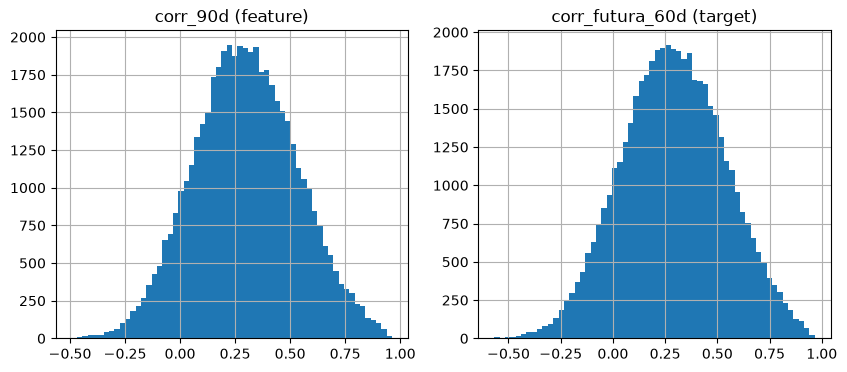

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
dataset["corr_90d"].hist(bins=60, ax=ejes[0]); ejes[0].set_title("corr_90d (feature)")
dataset["corr_futura_60d"].hist(bins=60, ax=ejes[1]); ejes[1].set_title("corr_futura_60d (target)")
plt.show()

## 7. ¿Qué tan bien predice la correlación pasada a la futura?

Si `corr_90d` ya fuera casi igual al target, el modelo no aportaría. Miramos la relación y la
correlación de cada feature con el target.

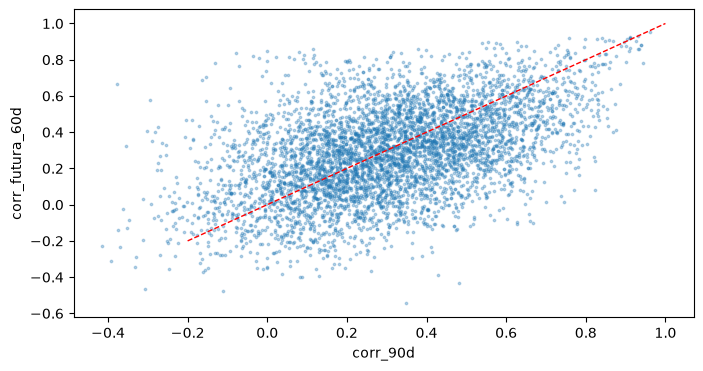

corr_30d               0.441
corr_90d               0.484
corr_250d              0.449
mismo_sector           0.222
dif_volatilidad       -0.154
dif_beta              -0.267
volatilidad_mercado    0.127
Name: corr_futura_60d, dtype: float64

In [9]:
muestra = dataset.sample(5000, random_state=0)
plt.scatter(muestra["corr_90d"], muestra["corr_futura_60d"], s=3, alpha=0.3)
plt.plot([-0.2, 1], [-0.2, 1], "r--", lw=1)
plt.xlabel("corr_90d"); plt.ylabel("corr_futura_60d")
plt.show()

dataset.drop(columns=["accion_id_1", "accion_id_2", "fecha_corte"]).corr()["corr_futura_60d"].drop("corr_futura_60d").round(3)